# Módulo 4: Aprendizaje Automático (Machine Learning)
## Semana 2 - Clase 5: Taller Comparativo de Clasificadores

En la clase anterior utilizamos **Regresión Logística** para predecir categorías. Sin embargo, en la Inteligencia Artificial existe el teorema del *"No Free Lunch"* (No hay almuerzo gratis), que dicta que **ningún algoritmo es perfecto para todos los problemas**.

Hoy realizaremos un **Taller Comparativo** paso a paso. Usaremos un dataset químico de **Vinos** y enfrentaremos a 3 algoritmos con filosofías radicalmente distintas para ver cómo "piensan" y cómo toman decisiones:

1. **k-Nearest Neighbors (k-NN):** Filosofía basada en Similitud y Distancia (Geometría).
2. **Árboles de Decisión:** Filosofía basada en Reglas Lógicas (If-Then).
3. **Naive Bayes:** Filosofía basada en Probabilidad Teórica.

---
## **Paso 1: Extracción y Exploración de Datos**

Utilizaremos el famoso dataset *Wine Quality* incluido en `scikit-learn`. El objetivo es predecir de qué **cultivo (Clase 0, 1 o 2)** proviene un vino basándonos en sus componentes químicos.

### Diccionario de Datos (Traducción al Español)
Dado que las bases de datos originales están en inglés, aquí detallamos el propósito de cada columna para entender la química del vino:
- **Alcohol:** Grado alcohólico del vino.
- **Acido_Malico (Malic Acid):** Un ácido natural del vino que da sabor agrio.
- **Ceniza (Ash):** Cantidad de material inorgánico restante tras la evaporación.
- **Alcalinidad_Ceniza (Alcalinity of Ash):** Medida de qué tan alcalina es la ceniza.
- **Magnesio (Magnesium):** Mineral presente en el vino.
- **Fenoles_Totales (Total Phenols):** Compuestos químicos que afectan el sabor y color.
- **Flavonoides (Flavanoids):** Antioxidantes naturales en la uva.
- **Fenoles_No_Flavonoides:** Otro tipo de compuesto aromático.
- **Proantocianidinas:** Taninos que dan estructura y astringencia al vino.
- **Intensidad_Color:** Qué tan oscuro es el vino.
- **Matiz (Hue):** Tonalidad del color del vino.
- **OD280_OD315:** Medida de dilución del vino (prueba de pureza de proteínas).
- **Prolina (Proline):** Un aminoácido principal presente en la uva.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultar advertencias para una clase más limpia
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

# Mapeo para traducir las columnas al español y facilitar la comprensión
mapeo_columnas = {
    'alcohol': 'Alcohol',
    'malic_acid': 'Acido_Malico',
    'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas',
    'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz',
    'od280/od315_of_diluted_wines': 'OD280_OD315',
    'proline': 'Prolina'
}

X.rename(columns=mapeo_columnas, inplace=True)
print("Datos cargados y columnas traducidas al español exitosamente.")

Datos cargados y columnas traducidas al español exitosamente.


Veamos los primeros 5 registros para comprobar la traducción y los datos.

In [2]:
display(X.head())

,Alcohol,Acido_Malico,Ceniza,Alcalinidad_Ceniza,Magnesio,Fenoles_Totales,Flavonoides,Fenoles_No_Flavonoides,Proantocianidinas,Intensidad_Color,Matiz,OD280_OD315,Prolina
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Ahora veamos cómo están distribuidas las clases (lo que queremos predecir). ¿Están balanceadas?

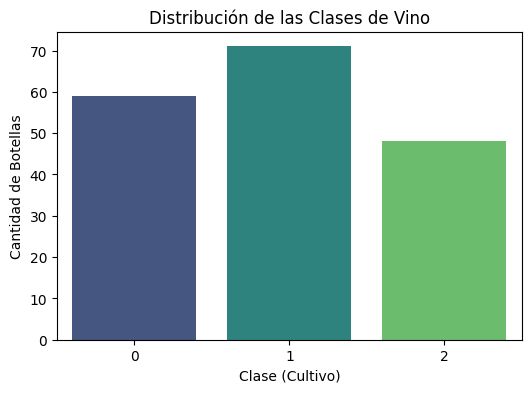

In [3]:
plt.figure(figsize=(6,4))
sns.countplot(x=y, palette='viridis')
plt.title('Distribución de las Clases de Vino')
plt.xlabel('Clase (Cultivo)')
plt.ylabel('Cantidad de Botellas')
plt.show()

---
## **Paso 2: Separación de Datos (Train/Test Split)**

Como siempre, debemos ocultarle una parte de los datos a nuestros algoritmos para poder examinarlos al final de la clase.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f"Datos para entrenar (aprender): {X_train.shape[0]} botellas.")
print(f"Datos para evaluar (examen): {X_test.shape[0]} botellas.")

Datos para entrenar (aprender): 124 botellas.
Datos para evaluar (examen): 54 botellas.


---
## **Paso 3: Modelo 1 - k-Nearest Neighbors (k-NN)**

**Filosofía:** "Dime con quién andas y te diré quién eres".
El algoritmo de los $k$ vecinos más cercanos no calcula fórmulas. Cuando llega un vino nuevo, simplemente mide la distancia geométrica hacia los otros vinos. Si le decimos que $k=5$, buscará los 5 vinos más parecidos y hará una votación.

**EL PELIGRO:** Como usa distancias matemáticas, las columnas con números grandes arruinarán el cálculo frente a columnas con números pequeños.

**Demostración del problema:** Observemos el tamaño de los números en nuestros datos crudos.

In [5]:
print("Valores máximos sin escalar:")
display(X_train[['Alcohol', 'Magnesio', 'Prolina']].max())

Valores máximos sin escalar:


Alcohol       14.83
Magnesio     162.00
Prolina     1515.00
dtype: float64

¡La Prolina llega a más de 1600 mientras el Alcohol apenas a 14! k-NN creerá falsamente que la Prolina es más importante. 
**Solución Obligatoria:** Estandarizar (Escalar) los datos.

In [6]:
from sklearn.preprocessing import StandardScaler

# 1. Instanciamos el escalador
scaler = StandardScaler()

# 2. Escalamos los datos de entrenamiento y de prueba
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

print("¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.")

¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.


Ahora sí, entrenemos a nuestro clasificador k-NN y veamos qué tan exacto es.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 3. Instanciar y Entrenar
knn = KNeighborsClassifier(n_neighbors=5) # Elegimos buscar a los 5 vecinos más cercanos
knn.fit(X_train_esc, y_train)

# 4. Predecir y Evaluar
pred_knn = knn.predict(X_test_esc)
acc_knn = accuracy_score(y_test, pred_knn)
print(f"Exactitud de k-NN: {acc_knn * 100:.2f}%")

Exactitud de k-NN: 94.44%


---
## **Paso 4: Modelo 2 - Árboles de Decisión**

**Filosofía:** el juego de "Adivina quién".
Un árbol de decisión no usa distancias, usa **reglas lógicas**. Busca la columna química que mejor parta los datos en grupos puros (bajando la *entropía* o la impureza de *Gini*).

*Nota: los árboles no necesitan datos escalados. Una regla como "¿Prolina > 700?" funciona igual sin importar qué tan grande sea el número.*

In [8]:
from sklearn.tree import DecisionTreeClassifier

# 1. Instanciar y Entrenar
# max_depth=3 significa que solo le permitiremos hacer 3 niveles de preguntas para evitar que se "memorice" los datos (Overfitting)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42) 
arbol.fit(X_train, y_train) # Usamos los datos originales (en español) sin escalar

# 2. Predecir y Evaluar
pred_arbol = arbol.predict(X_test)
acc_arbol = accuracy_score(y_test, pred_arbol)
print(f"Exactitud del Árbol de Decisión: {acc_arbol * 100:.2f}%")

Exactitud del Árbol de Decisión: 96.30%


**Visualización del árbol:**
Un árbol se puede leer. El gráfico muestra qué pregunta hizo en cada nodo y sobre qué columna, y los nombres salen en español porque renombramos las columnas al principio.

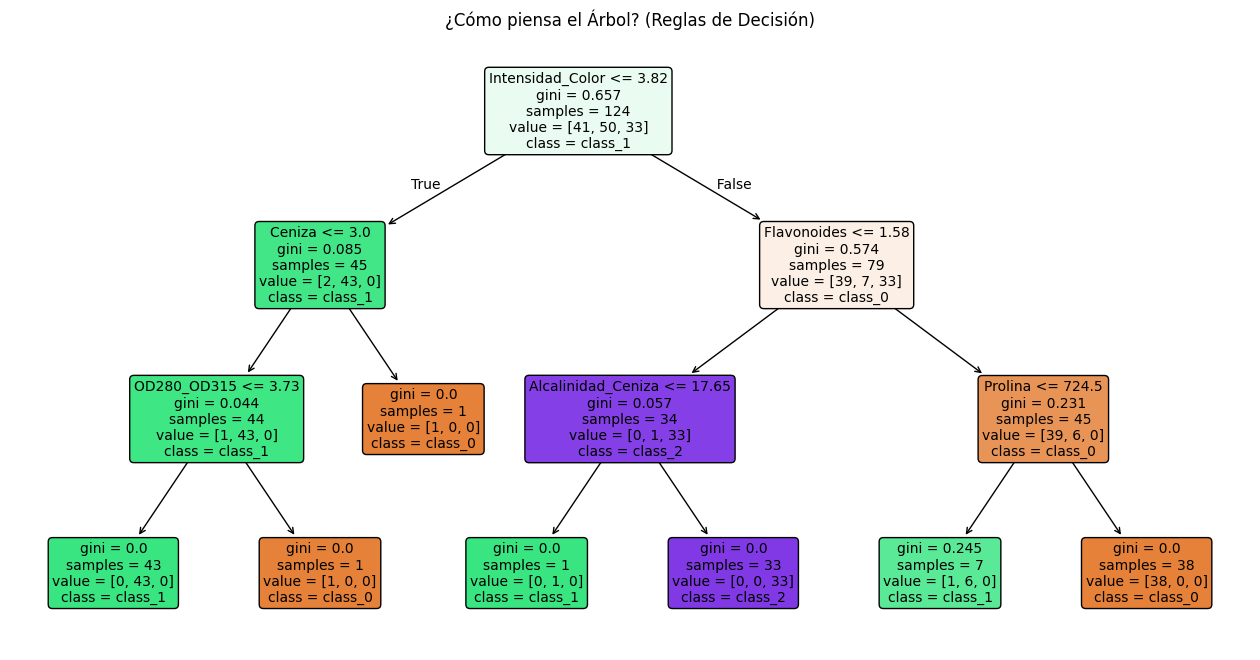

In [9]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(arbol, 
          feature_names=X.columns, # Usamos nuestras nuevas columnas en español
          class_names=datos_vino.target_names, 
          filled=True, 
          rounded=True,
          fontsize=10)
plt.title('¿Cómo piensa el Árbol? (Reglas de Decisión)')
plt.show()

---
## **Paso 5: Modelo 3 - Naive Bayes**

**Filosofía:** Probabilidad Pura (Teorema de Bayes).
Se llama "Ingenuo" (*Naive*) porque asume que el nivel de Alcohol no tiene relación matemática con el Magnesio. En la realidad esto es falso, pero asumir esa ingenuidad hace que el cálculo de probabilidades sea **extremadamente rápido**.

In [10]:
from sklearn.naive_bayes import GaussianNB

# 1. Instanciar y Entrenar
bayes = GaussianNB()
bayes.fit(X_train, y_train)

# 2. Predecir y Evaluar
pred_bayes = bayes.predict(X_test)
acc_bayes = accuracy_score(y_test, pred_bayes)
print(f"Exactitud de Naive Bayes: {acc_bayes * 100:.2f}%")

Exactitud de Naive Bayes: 100.00%


---
## **Paso 6: Comparación de fronteras de decisión**

Para ver cómo corta cada algoritmo, reduzco el dataset a **2 columnas** (`Alcohol` y `Flavonoides`) y lo grafico en un plano de 2 dimensiones.

Así se ve la frontera de decisión de cada modelo, es decir, cómo divide el plano para clasificar los vinos.

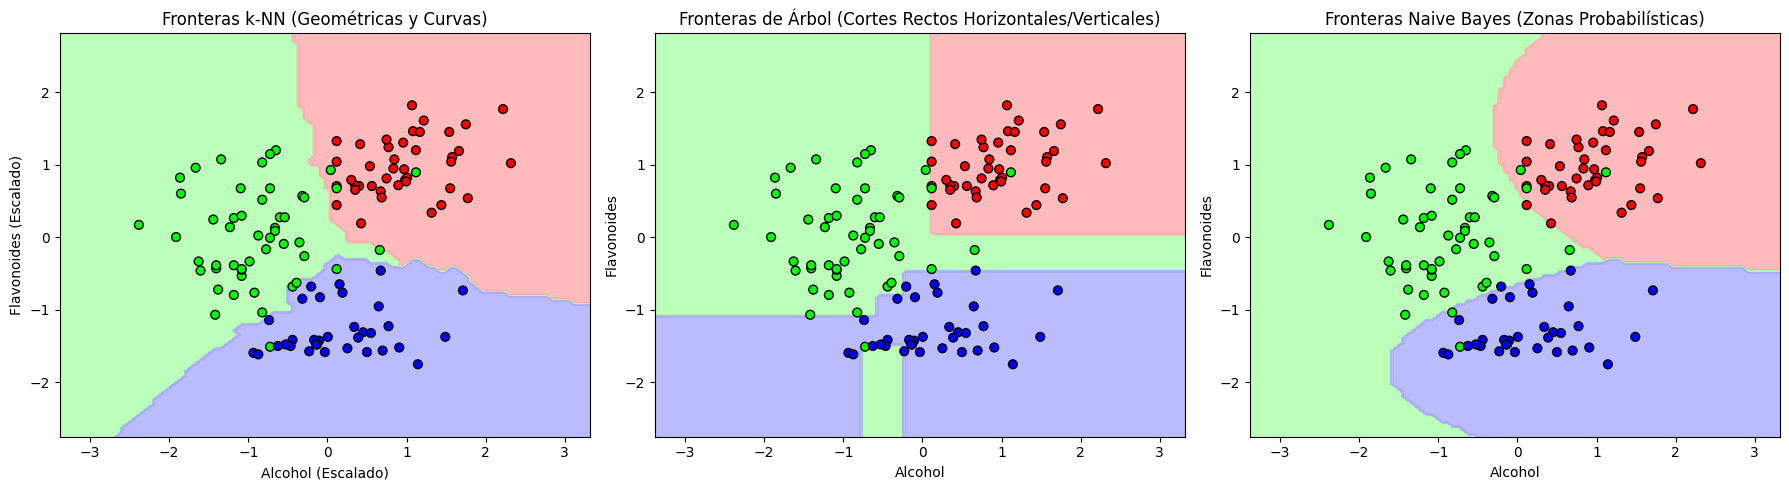

In [11]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

# Para poder graficar en 2D, elegimos solo 2 características.
X_2D = X_train[['Alcohol', 'Flavonoides']]

# k-NN sufre si no lo escalamos, así que escalamos estas 2 columnas
scaler_2d = StandardScaler()
X_2D_esc = scaler_2d.fit_transform(X_2D)

# Entrenamos 3 modelos "miniaturas" que solo ven estas 2 columnas
knn_2d = KNeighborsClassifier(n_neighbors=5).fit(X_2D_esc, y_train)
arbol_2d = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_2D_esc, y_train)
bayes_2d = GaussianNB().fit(X_2D_esc, y_train)

# Configuración del gráfico (3 paneles)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

# --- 1. Panel de k-NN ---
DecisionBoundaryDisplay.from_estimator(knn_2d, X_2D_esc, response_method='predict', cmap=cmap_light, ax=ax1, alpha=0.8)
ax1.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax1.set_title("Fronteras k-NN (Geométricas y Curvas)")
ax1.set_xlabel('Alcohol (Escalado)')
ax1.set_ylabel('Flavonoides (Escalado)')

# --- 2. Panel de Árbol de Decisión ---
DecisionBoundaryDisplay.from_estimator(arbol_2d, X_2D_esc, response_method='predict', cmap=cmap_light, ax=ax2, alpha=0.8)
ax2.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax2.set_title("Fronteras de Árbol (Cortes Rectos Horizontales/Verticales)")
ax2.set_xlabel('Alcohol')
ax2.set_ylabel('Flavonoides')

# --- 3. Panel de Naive Bayes ---
DecisionBoundaryDisplay.from_estimator(bayes_2d, X_2D_esc, response_method='predict', cmap=cmap_light, ax=ax3, alpha=0.8)
ax3.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax3.set_title("Fronteras Naive Bayes (Zonas Probabilísticas)")
ax3.set_xlabel('Alcohol')
ax3.set_ylabel('Flavonoides')

plt.tight_layout()
plt.show()

Qué se ve en las gráficas:
* **k-NN** dibuja fronteras curvas e irregulares que rodean a los grupos de puntos.
* **Árbol de decisión** solo hace cortes rectos, horizontales y verticales, porque cada regla es un "mayor que" o "menor que" sobre una columna.
* **Naive Bayes** deja zonas amplias y suaves, que vienen de las campanas de distribución de cada clase.

---
## **Paso 7: Comparación de desempeño y conclusión**

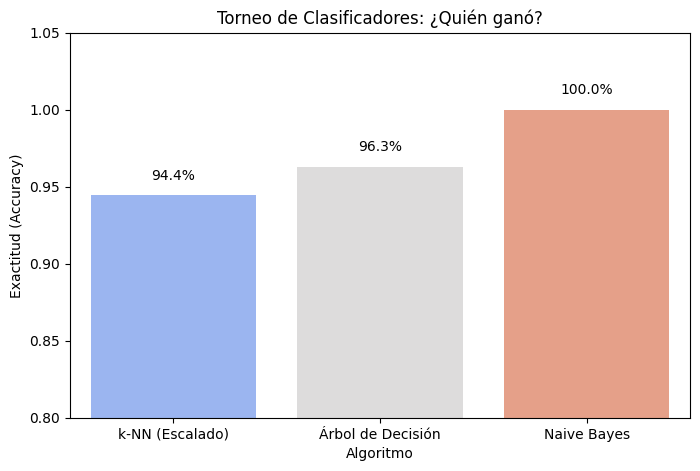

In [12]:
# Crear un DataFrame con los resultados
resultados = pd.DataFrame({
    'Algoritmo': ['k-NN (Escalado)', 'Árbol de Decisión', 'Naive Bayes'],
    'Exactitud (Accuracy)': [acc_knn, acc_arbol, acc_bayes]
})

# Graficar comparativa
plt.figure(figsize=(8,5))
sns.barplot(x='Algoritmo', y='Exactitud (Accuracy)', data=resultados, palette='coolwarm')
plt.title('Torneo de Clasificadores: ¿Quién ganó?')
plt.ylim(0.8, 1.05) # Enfocar el gráfico en la parte alta para notar las diferencias

# Agregar etiquetas de porcentaje en las barras
for index, row in resultados.iterrows():
    plt.text(index, row['Exactitud (Accuracy)'] + 0.01, f"{row['Exactitud (Accuracy)']*100:.1f}%", color='black', ha="center")

plt.show()

### **Conclusión**
En este dataset las exactitudes de los tres modelos quedan parejas, así que la elección depende más del problema que del porcentaje:
* Si hay que explicar **por qué** se tomó una decisión (una auditoría médica o legal, por ejemplo), el árbol de decisión es el único que lo muestra de forma visual.
* Con un dataset enorme, como 5 millones de correos, k-NN se vuelve lento porque compara cada caso nuevo contra todos los datos. Naive Bayes lo resuelve en segundos.
* Cuando las fronteras entre clases son curvas y complejas, k-NN suele adaptarse bien.

---
## **Paso 8: Mapa de calor, tercera característica y comparación de modelos**

Aquí busco qué columna, además de `Alcohol` y `Flavonoides`, representa mejor la clase de vino. Uso un mapa de calor de correlaciones y después comparo qué modelo dibuja la frontera de clasificación más clara.

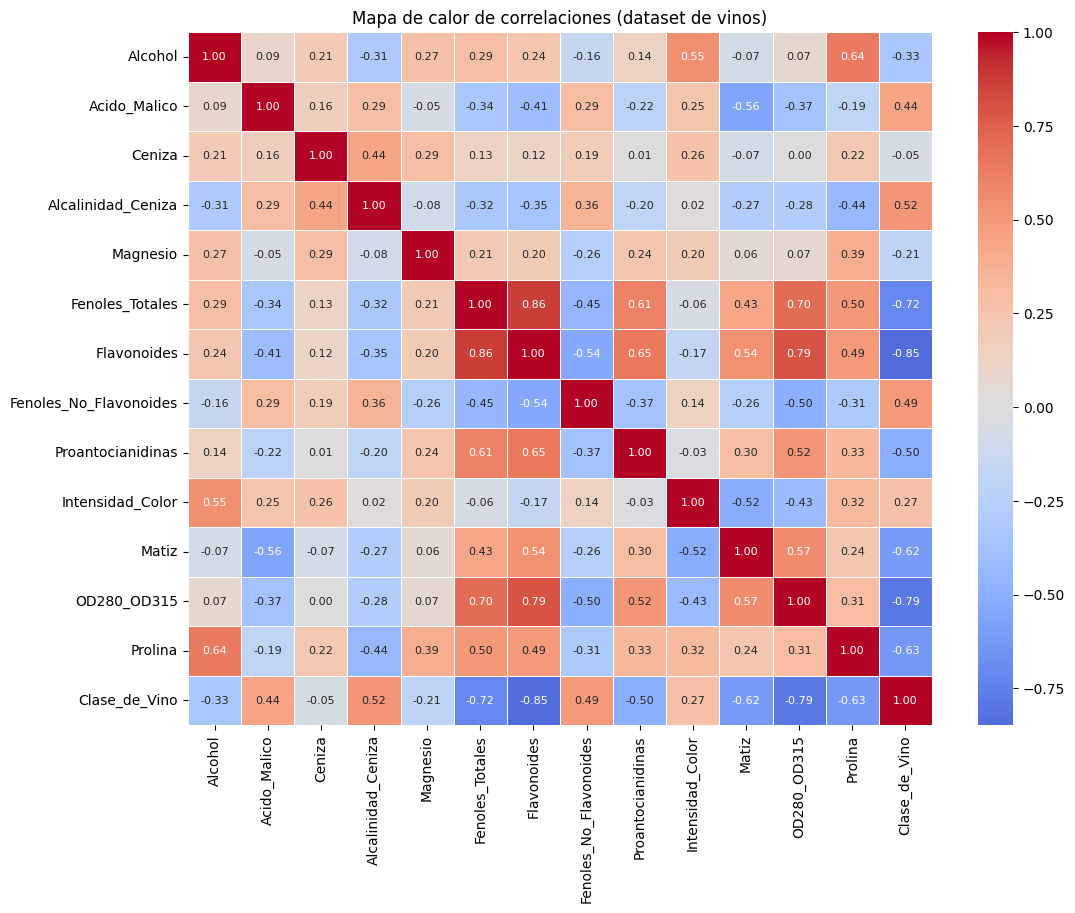

In [13]:
# Unimos las columnas con la clase para correlacionar todo junto
df_corr = X.copy()
df_corr['Clase_de_Vino'] = y

plt.figure(figsize=(12, 9))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Mapa de calor de correlaciones (dataset de vinos)')
plt.show()

In [14]:
# Ordenamos las columnas por su correlación (en valor absoluto) con la clase
corr_clase = df_corr.corr()['Clase_de_Vino'].drop('Clase_de_Vino')
ranking = corr_clase.abs().sort_values(ascending=False)
print("Correlación absoluta con la clase (top 5):")
print(ranking.head(5).round(3))
print("\nPuesto de Alcohol:", list(ranking.index).index('Alcohol') + 1, "de", len(ranking))

tercera = ranking.index[2]
print(f"\nTercera característica más representativa: {tercera}")
print(f"Correlación de {tercera} con Flavonoides: {df_corr[tercera].corr(df_corr['Flavonoides']):.2f}")

Correlación absoluta con la clase (top 5):
Flavonoides        0.847
OD280_OD315        0.788
Fenoles_Totales    0.719
Prolina            0.634
Matiz              0.617
Name: Clase_de_Vino, dtype: float64

Puesto de Alcohol: 10 de 13

Tercera característica más representativa: Fenoles_Totales
Correlación de Fenoles_Totales con Flavonoides: 0.86


Ordené las columnas por su correlación con la clase. `Flavonoides` es la primera, `OD280_OD315` la segunda y `Fenoles_Totales` la tercera, así que esa es la que uso.

Dos detalles: `Fenoles_Totales` y `Flavonoides` están muy correlacionadas entre sí, o sea que aportan información parecida. Y `Alcohol` queda en el puesto 10 por sí sola, pero combinada con otra columna ayuda a separar la clase 0 de la 1.

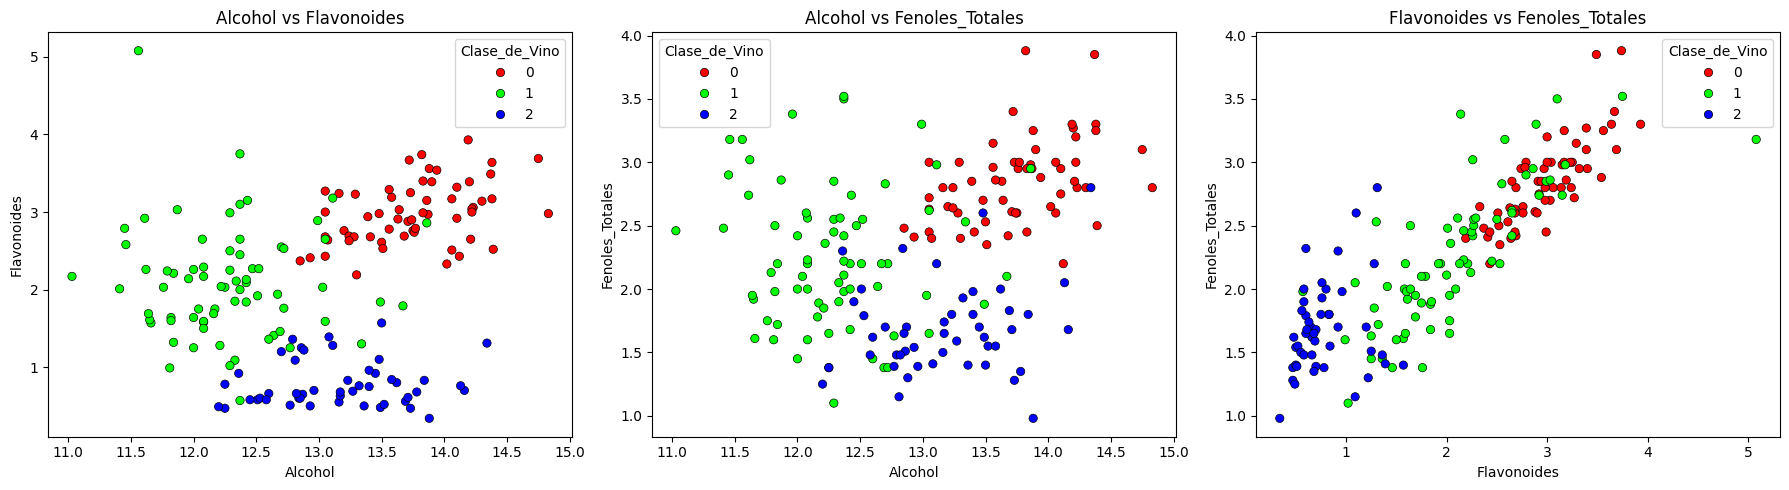

In [15]:
# Los tres pares: Alcohol vs Flavonoides, Alcohol vs tercera, Flavonoides vs tercera
pares = [('Alcohol', 'Flavonoides'), ('Alcohol', tercera), ('Flavonoides', tercera)]

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, (a, b) in zip(axs, pares):
    sns.scatterplot(x=X[a], y=X[b], hue=y, palette=['#FF0000', '#00FF00', '#0000FF'],
                    edgecolor='k', ax=ax)
    ax.set_title(f'{a} vs {b}')
plt.tight_layout()
plt.show()

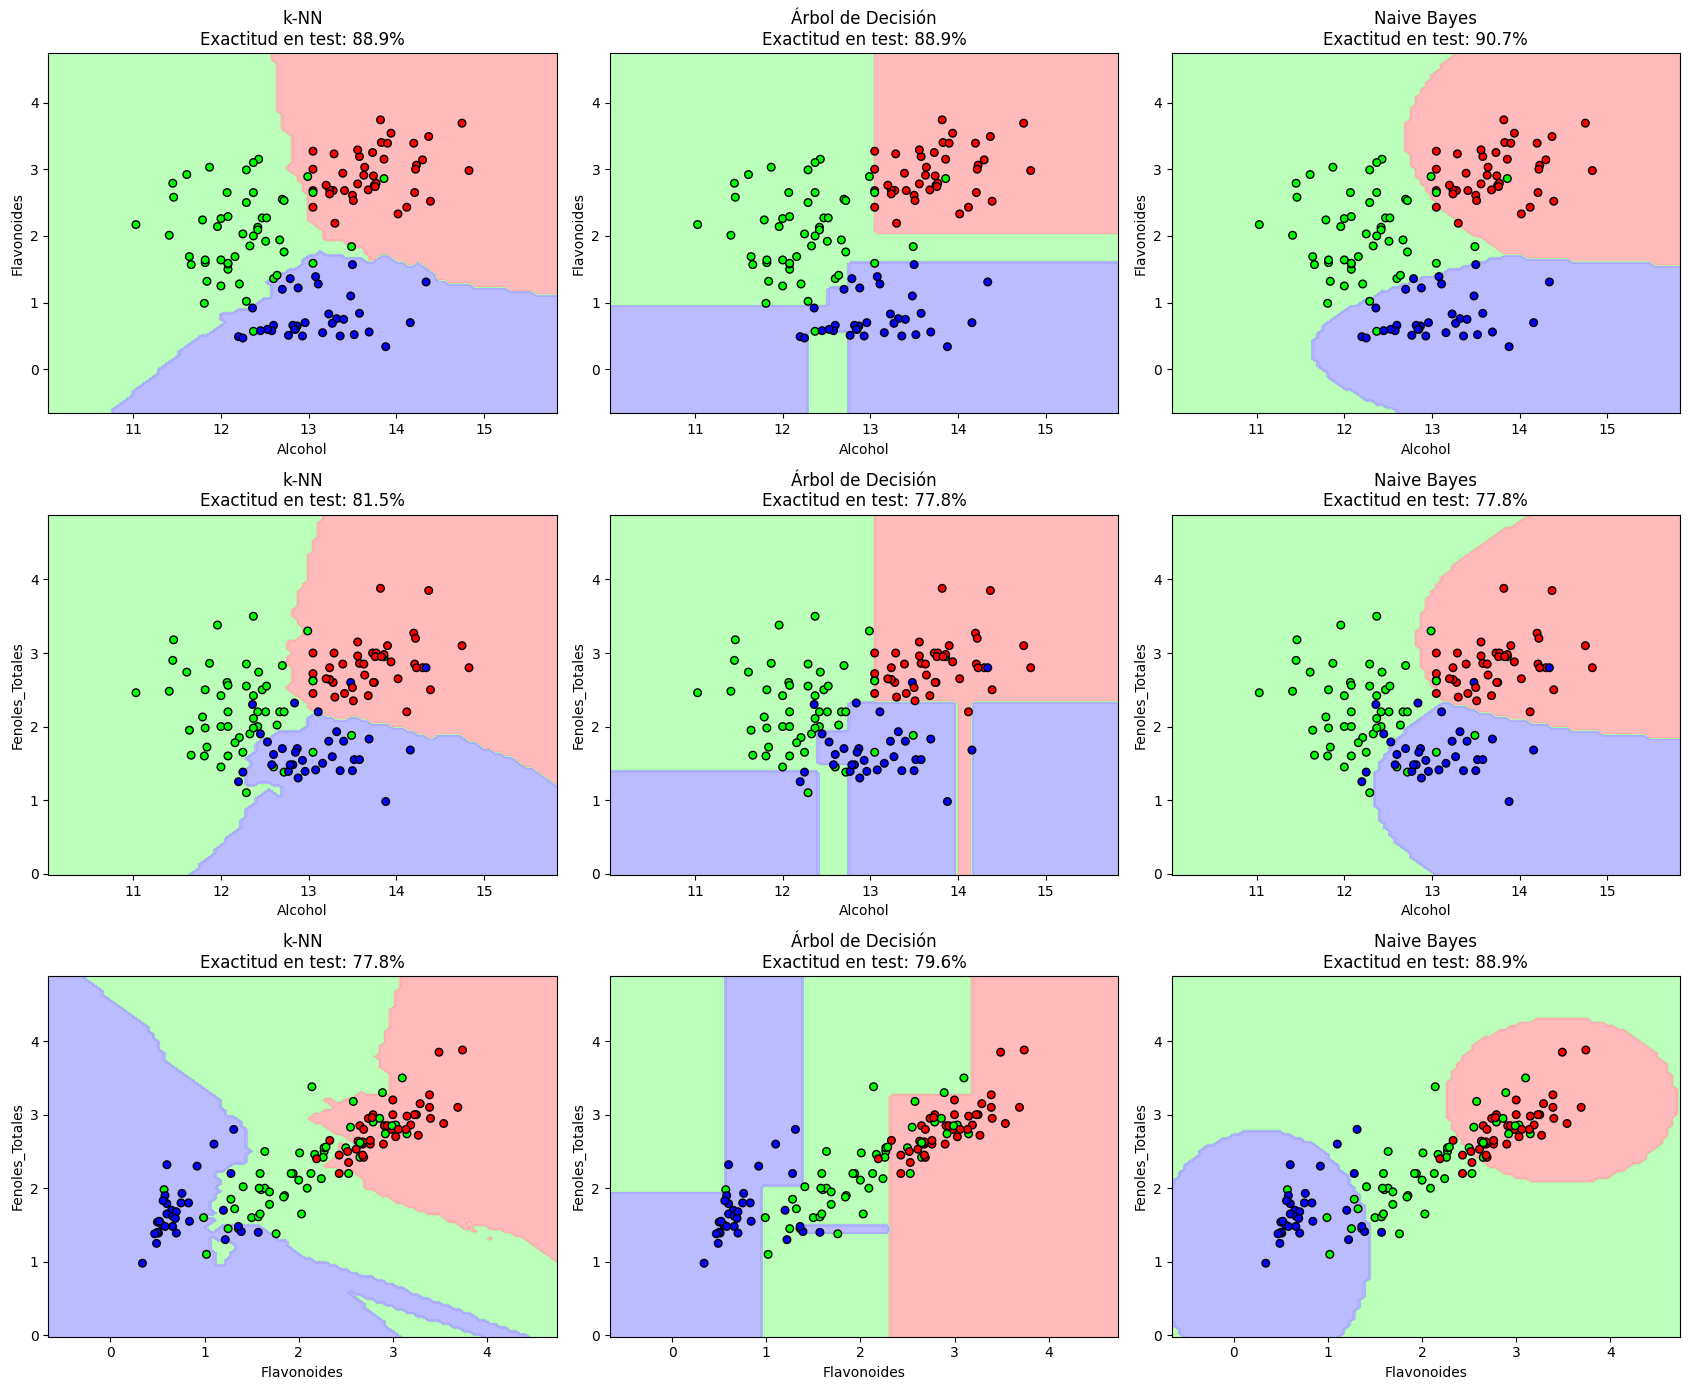

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

# Cada modelo lleva su escalador dentro (el árbol y Naive Bayes no lo necesitan, pero no les afecta)
modelos = {
    'k-NN': lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Árbol de Decisión': lambda: make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=4, random_state=42)),
    'Naive Bayes': lambda: make_pipeline(StandardScaler(), GaussianNB()),
}
cmap_fondo = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_puntos = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

filas = []
fig, axs = plt.subplots(3, 3, figsize=(17, 14))
for i, (a, b) in enumerate(pares):
    for j, (nombre, crear) in enumerate(modelos.items()):
        modelo = crear().fit(X_train[[a, b]], y_train)
        acc_test = modelo.score(X_test[[a, b]], y_test)
        acc_cv = cross_val_score(crear(), X[[a, b]], y, cv=5).mean()
        filas.append((f'{a} vs {b}', nombre, acc_test, acc_cv))

        DecisionBoundaryDisplay.from_estimator(modelo, X_train[[a, b]], response_method='predict',
                                               cmap=cmap_fondo, ax=axs[i, j], alpha=0.8)
        axs[i, j].scatter(X_train[a], X_train[b], c=y_train, cmap=cmap_puntos, edgecolor='k', s=30)
        axs[i, j].set_title(f'{nombre}\nExactitud en test: {acc_test:.1%}')

plt.tight_layout()
plt.show()

In [17]:
tabla = pd.DataFrame(filas, columns=['Par', 'Modelo', 'Exactitud test', 'Exactitud CV (5 pliegues)'])
display(tabla.round(3))

,Par,Modelo,Exactitud test,Exactitud CV (5 pliegues)
0,Alcohol vs Flavonoides,k-NN,0.889,0.916
1,Alcohol vs Flavonoides,Árbol de Decisión,0.889,0.877
2,Alcohol vs Flavonoides,Naive Bayes,0.907,0.911
3,Alcohol vs Fenoles_Totales,k-NN,0.815,0.854
4,Alcohol vs Fenoles_Totales,Árbol de Decisión,0.778,0.815
5,Alcohol vs Fenoles_Totales,Naive Bayes,0.778,0.843
6,Flavonoides vs Fenoles_Totales,k-NN,0.778,0.743
7,Flavonoides vs Fenoles_Totales,Árbol de Decisión,0.796,0.776
8,Flavonoides vs Fenoles_Totales,Naive Bayes,0.889,0.787


### **Conclusión del Paso 8**

* **Tercera característica:** `Fenoles_Totales`, con una correlación de -0.72 con la clase. Está muy ligada a `Flavonoides` (0.86), así que en el par `Flavonoides` vs `Fenoles_Totales` los puntos forman una diagonal y las clases 0 y 1 se mezclan en el centro. En `Alcohol` vs `Fenoles_Totales` se mezclan las clases 1 y 2.
* **Mejor par:** `Alcohol` vs `Flavonoides`. Con ese par los tres modelos llegan a 87.7 %-91.6 % en validación cruzada, mientras que con los otros dos pares quedan entre 74 % y 85 %.
* **Modelo con la gráfica más clara:** Naive Bayes. Sobre el mejor par saca 90.7 % en test y 91.1 % en validación cruzada, y dibuja tres zonas continuas con bordes suaves. k-NN tiene una exactitud casi igual (91.6 % en validación cruzada), pero su frontera es irregular y se mete entre puntos sueltos. El árbol hace rectángulos y franjas angostas que dependen más de los cortes que de un patrón real.
* **Ojo con la exactitud:** con 54 vinos de prueba, la diferencia entre Naive Bayes (90.7 %) y k-NN (88.9 %) es de un solo vino. Por eso me baso más en qué tan clara se ve la frontera que en ese porcentaje.